# 1. Data Generation

I built a simulator to create synthetic flight data for badminton shuttlecocks. The dataset includes ideal projectile data without air drag, realistic flight data with quadratic air drag, and separate datasets for extrapolation tests.

Shuttlecocks have strong quadratic air drag, so the simple ideal projectile formula cannot accurately describe their movement. I used the Euler method to solve the motion ordinary differential equations step by step.

Equations used:
$$
\begin{align*}
drag\_force_x &= -drag\_coeff \cdot \sqrt{vx^2+vy^2} \cdot vx \\
drag\_force_y &= -drag\_coeff \cdot \sqrt{vx^2+vy^2} \cdot vy \\
ax &= \frac{drag\_force_x}{mass} \\
ay &= -g + \frac{drag\_force_y}{mass} \\
vx_{new} &= vx + ax \cdot dt \\
vy_{new} &= vy + ay \cdot dt \\
x_{new} &= x + vx \cdot dt \\
y_{new} &= y + vy \cdot dt
\end{align*}
$$

Variables:
- `drag_coeff`: drag coefficient for the shuttlecock. In the main data generation loop, this variable is named `drag`.
- `mass`: mass of the shuttlecock (0.005 kg)
- `vx`, `vy`: horizontal and vertical velocity
- `ax`, `ay`: horizontal and vertical acceleration
- `dt`: small time step for Euler simulation
- `g`: gravitational acceleration, 9.8 m/s²
- `x`, `y`: horizontal and vertical position

$g=9.8\ \text{m/s}^2$, $mass=0.005\ \text{kg}$, which is the real mass of a shuttlecock.
The program keeps updating velocity and position until the shuttle hits the ground ($y \le 0$). I randomly choose initial speed `v0`, launch angle and drag_coeff value for each simulation run.

Three CSV output files:
1. `range_dataset.csv`: 3000 simulation samples. It saves initial physical parameters (`v0`, angle, `mass`, drag_coeff), ideal projectile range and real landing range.Initial speed v0 is sampled between 20 m/s and 40 m/s, training launch angles are 30°‑45°(initial speed and launch angle ranges cover shots from ordinary amateur players up to professional athletes),Drag coefficient varies from 0.0009 to 0.0013. This dataset is used for traditional machine learning models (linear regression and random forest). I split it into training set and in-distribution test set.
2. `traj_observation.csv`: Observation points prepared for the PINN model. For each flight trajectory, I evenly pick 25 points and record `t`, `x`, `y` values.
3. `extrapolation_range_test.csv`: 600 out-of-distribution test samples. The launch angles are between 50–60°, outside the training angle range (30–45°). This set tests whether the model can make predictions under new, unseen physical conditions.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error,mean_absolute_error


import torch
import torch.nn as nn
import torch.optim as optim
# set device: use GPU if available, else CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on device:", device)

# set constants and random seed to get same dataset every run
g = 9.8
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def simulate_projectile_trajectory(v0, theta, mass, drag_coeff, dt=0.01, initial_height=1.8):
    # Simulate badminton flight, use explicit Euler to solve ODE
    # initial_height = 1.8m is the real hitting height for badminton high‑clear
    # old version: initial y set to 0, only suitable for ground launch
    # x, y = 0.0, 0.0

    theta_rad = np.radians(theta)
    vx = v0 * np.cos(theta_rad)
    vy = v0 * np.sin(theta_rad)

    x, y = 0.0, initial_height
    t = 0.0

    t_list, x_list, y_list = [], [], []

    # keep looping until the shuttle hits the ground
    while y >= 0:
        t_list.append(t)
        x_list.append(x)
        y_list.append(y)

        # calculate quadratic air drag force
        v_mag = np.sqrt(vx**2 + vy**2)   #velocity magnitude
        drag_force_x = - drag_coeff * v_mag * vx
        drag_force_y = - drag_coeff * v_mag * vy

        ax = drag_force_x / mass
        ay = -g + drag_force_y / mass

        # Euler method update velocity and position
        vx += ax * dt
        vy += ay * dt
        x += vx * dt
        y += vy * dt
        t += dt

    final_range = x
    return np.array(t_list), np.array(x_list), np.array(y_list), final_range

# ---------------------- generate main dataset ----------------------
sample_num = 3000
mass_badminton = 0.005   # real mass of badminton: 5 grams
end_records = []          # store params and landing range for traditional ML
pinn_observation_list = []# store sampled t‑x‑y points for PINN

for idx in range(sample_num):
    # sample parameters for badminton high‑clear
    v0 = np.random.uniform(20, 40)
    # angle = np.random.uniform(15, 75) old angle range for general projectile: 15 ~ 75 degree, not fit for real badminton
    angle = np.random.uniform(30, 45)       # training angle range for high clear
    # drag = np.random.uniform(0, 0.03) early test: drag 0 ~ 0.03, too large, shuttle slows down unrealistically fast
    drag = np.random.uniform(0.0009, 0.0013) # merged drag constant

    t_arr, x_arr, y_arr, real_range = simulate_projectile_trajectory(
        v0, angle, mass_badminton, drag, dt=0.001, initial_height=1.8
    )

    theta_r = np.radians(angle)
    # ideal range formula, note: not fully accurate for 1.8m launch height, just for reference
    ideal_range = (v0 ** 2 * np.sin(2 * theta_r)) / g

    end_records.append([v0, angle, mass_badminton, drag, ideal_range, real_range])

    # pick 25 points evenly from one trajectory for PINN input
    # Originally I tried saving every time step, but csv file became huge
    # So down‑sample instead of storing full trajectory
    n_obs_points = 25
    sample_indices = np.linspace(0, len(t_arr) - 1, n_obs_points, dtype=int)
    for i in sample_indices:
        pinn_observation_list.append({
            "sample_id": idx,
            "v0": v0,
            "angle": angle,
            "mass": mass_badminton,
            "drag_coeff": drag,
            "t": t_arr[i],
            "x": x_arr[i],
            "y": y_arr[i]
        })

# save data to csv
df_end = pd.DataFrame(end_records, columns=["v0", "angle", "mass", "drag_coeff", "ideal_range", "real_range"])
df_end.to_csv("range_dataset.csv", index=False)

df_pinn_obs = pd.DataFrame(pinn_observation_list)
df_pinn_obs.to_csv("traj_observation.csv", index=False)

print("Main dataset done.")

# ---------------------- generate extrapolation test set ----------------------
extrap_sample_num = 600
extrap_end_records = []

for idx in range(extrap_sample_num):
    # extrapolation set:  outside training range 50‑60°
    v0_ext = np.random.uniform(20, 40)
    angle_ext = np.random.uniform(50, 60)
    drag_ext = np.random.uniform(0.0009, 0.0013)
 

    t_ext, x_ext, y_ext, real_range_ext = simulate_projectile_trajectory(
        v0_ext, angle_ext, mass_badminton, drag_ext, dt=0.01, initial_height=1.8
    )

    theta_r_ext = np.radians(angle_ext)
    ideal_range_ext = (v0_ext ** 2 * np.sin(2 * theta_r_ext)) / g
    extrap_end_records.append([v0_ext, angle_ext, mass_badminton, drag_ext, ideal_range_ext, real_range_ext])

df_extrap = pd.DataFrame(extrap_end_records, columns=["v0", "angle", "mass", "drag_coeff", "ideal_range", "real_range"])
df_extrap.to_csv("extrapolation_range_test.csv", index=False)

print("Extrapolation test set done.")

# --------------------------  Split training / interpolation test set --------------------------
# Split original 3000‑sample range dataset into training and interpolation test subsets.
# Interpolation test: all input parameters lie within training distribution, used to evaluate in‑distribution prediction performance.
# Task: learn mapping (v0, theta, mass, drag_coeff) -> range, regression problem

X_all = df_end[["v0", "angle", "mass", "drag_coeff"]].values  # Feature matrix: 4 physical input variables
y_all = df_end["real_range"].values  # Target label: real range with air‑drag

# 20% for interpolation test set, 80% for training set. Fixed seed for reproducible splits.
X_train, X_interp_test, y_train, y_interp_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED
)

# Load out‑of‑distribution extrapolation test data
X_extrap_test = df_extrap[["v0", "angle", "mass", "drag_coeff"]].values
y_extrap_test = df_extrap["real_range"].values



Running on device: cpu
Main dataset done.
Extrapolation test set done.


# 2. Exploratory Data Analysis

Exploratory Data Analysis (EDA) explores raw data before building machine learning models. It helps understand data distribution, feature ranges and relationships between variables.

This part includes:

- Basic statistics of the training set
- Histograms for each input feature
- Correlation heatmap
- Scatter plots to show relationships between variables

In [13]:
# =====================  Exploratory Data Analysis =====================
# visualise dataset, check distribution and correlation
# plt.rcParams["font.sans-serif"] = ["SimHei","Arial"] # used Chinese font before, removed, all plots use English now

plt.rcParams['font.family'] = 'DejaVu Sans'
# plt.rcParams["axes.unicode_minus"] = False # only needed for Chinese characters

df_train = pd.read_csv("range_dataset.csv")
# df_ext = pd.read_csv("extrapolation_range.csv")  # old filename, fixed
df_ext = pd.read_csv("extrapolation_range_test.csv")
df_traj = pd.read_csv("traj_observation.csv")

# print basic stats
print("=====Training set basic statistics=====")
print(df_train.describe())
print("\n=====Extrapolation set basic statistics=====")
print(df_ext.describe())




=====Training set basic statistics=====
                v0        angle      mass   drag_coeff  ideal_range  \
count  3000.000000  3000.000000  3000.000  3000.000000  3000.000000   
mean     30.088839    37.365849     0.005     0.001094    91.213229   
std       5.687625     4.348246     0.000     0.000116    33.505176   
min      20.002694    30.000175     0.005     0.000900    36.307323   
25%      25.142878    33.593234     0.005     0.000993    61.779998   
50%      30.209631    37.310499     0.005     0.001092    88.488035   
75%      35.045298    41.113555     0.005     0.001192   118.587370   
max      39.994353    44.993366     0.005     0.001300   163.218962   

        real_range  
count  3000.000000  
mean      9.555532  
std       1.151206  
min       6.687961  
25%       8.705251  
50%       9.495022  
75%      10.374460  
max      12.853306  

=====Extrapolation set basic statistics=====
               v0       angle     mass  drag_coeff  ideal_range  real_range
count  60

From the statistical table, I can see all generated data lie within expected bounds.
Input features and output targets are all inside our predefined simulation range.
I can also observe a massive gap between ideal drag‑free range and real range under quadratic air drag.

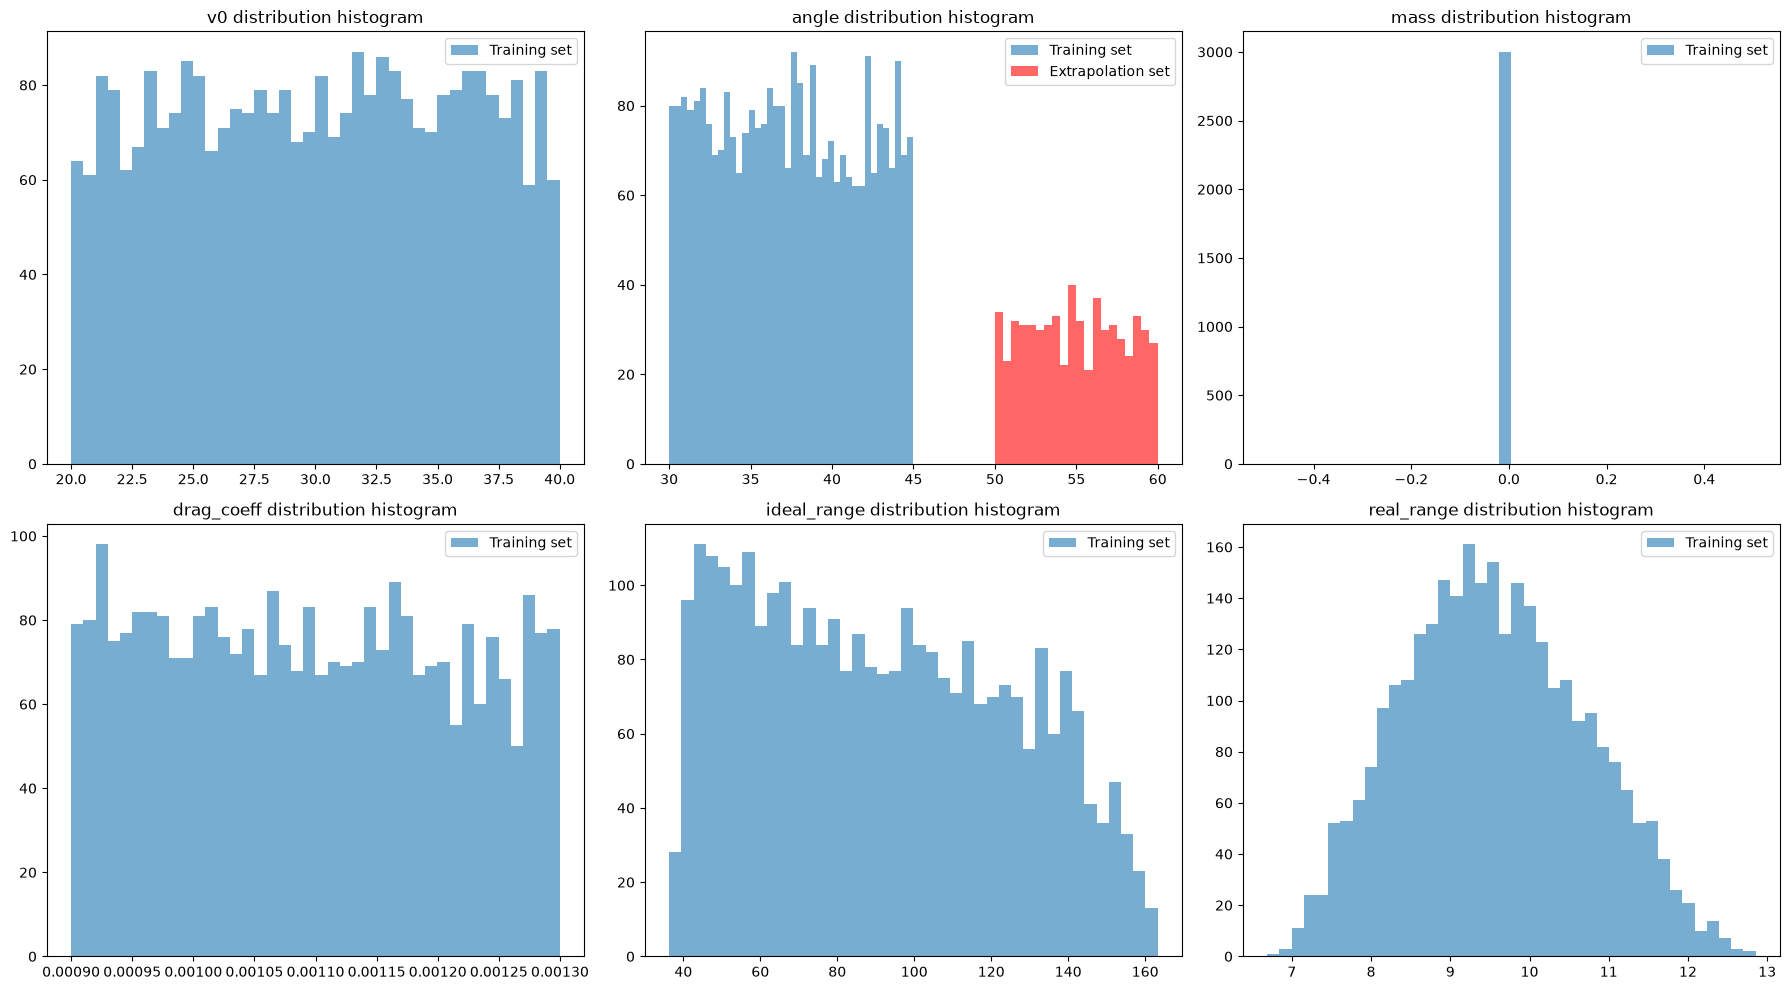

In [14]:
# 1. draw histogram for each feature
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
# old code used "drag", csv column name is drag_coeff, fixed key error
cols = ["v0", "angle", "mass", "drag_coeff", "ideal_range", "real_range"]
for i, col in enumerate(cols):
    axes[i].hist(df_train[col], bins=40, alpha=0.6, label="Training set")
    if col == "angle":
        axes[i].hist(df_ext[col], bins=20, color="red", alpha=0.6, label="Extrapolation set")
    axes[i].set_title(f"{col} distribution histogram")
    axes[i].legend()
    plt.tight_layout()
plt.savefig("eda_hist.png", dpi=200)
plt.show()

From the histograms, I can see initial velocity and drag coefficient are sampled uniformly within our given ranges. The launch angles of training data are 30‑45°, while the extrapolation test set uses 50‑60°, which are unseen during training. This helps test how the model performs on unfamiliar inputs.

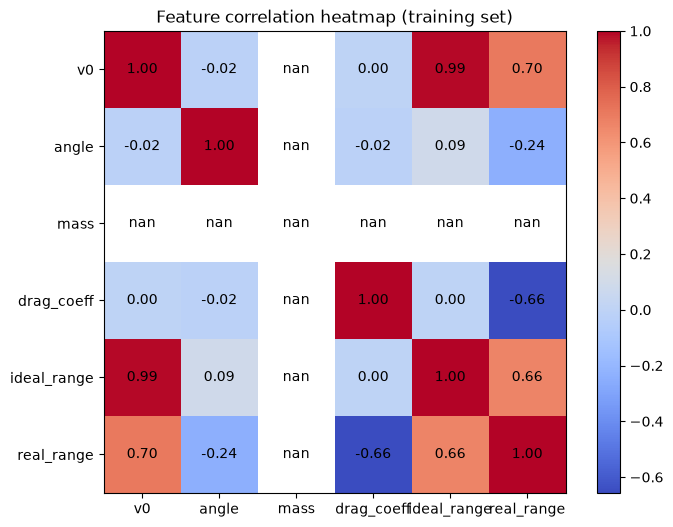

In [15]:
# 2. correlation heatmap
corr = df_train[["v0", "angle", "mass", "drag_coeff", "ideal_range", "real_range"]].corr().values
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm")
cols_name = ["v0", "angle", "mass", "drag_coeff", "ideal_range", "real_range"]
ax.set_xticks(np.arange(len(cols_name)))
ax.set_yticks(np.arange(len(cols_name)))
ax.set_xticklabels(cols_name)
ax.set_yticklabels(cols_name)
plt.colorbar(im)
# write correlation number on each cell
for i in range(len(cols_name)):
    for j in range(len(cols_name)):
        text = ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", color="black")
ax.set_title("Feature correlation heatmap (training set)")
plt.savefig("eda_corr.png", dpi=200)
plt.show()

Looking at this correlation heatmap, I can see several useful patterns.
The initial velocity `v0` has a really strong positive link with ideal range, and also a fairly strong positive link with real range. That makes sense: faster initial speed generally makes the shuttle fly farther.
The drag coefficient has a clear negative link with real range. When drag gets bigger, the flying distance becomes shorter, which matches what physics tells us.
Launch angle only has a small negative effect on landing distance. What’s more, `v0`, `angle` and `drag_coeff` hardly relate to each other. That means our random sampling did a good job — none of these inputs influence one another.
Mass is a constant for all samples, so NaN shows up here and we cannot work out its correlation.

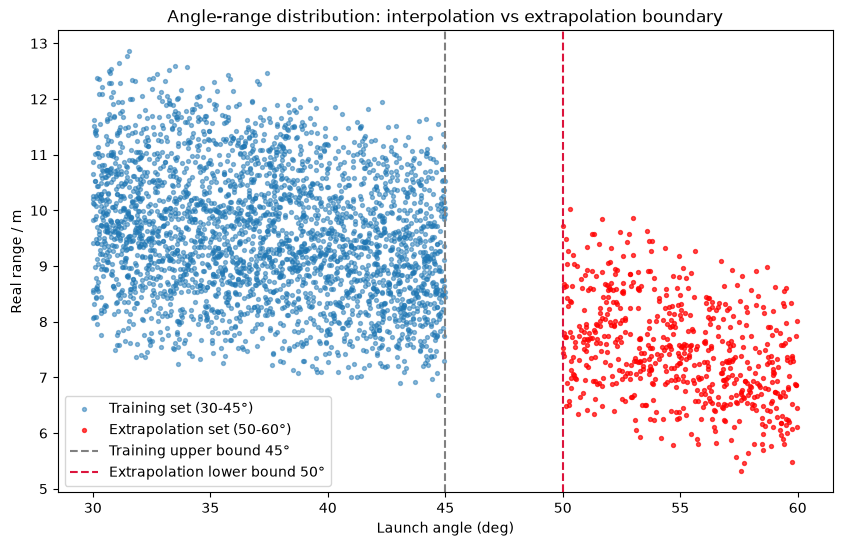

In [16]:
# 3. scatter: angle vs landing range
plt.figure(figsize=(10, 6))
# old labels for 15‑75° /80‑88°, updated for badminton high‑clear
plt.scatter(df_train["angle"], df_train["real_range"], s=8, alpha=0.5, label="Training set (30‑45°)")
plt.scatter(df_ext["angle"], df_ext["real_range"], s=8, alpha=0.7, c="red", label="Extrapolation set (50‑60°)")
plt.xlabel("Launch angle (deg)")
plt.ylabel("Real range / m")
# draw boundary line between train and extrapolation
plt.axvline(x=45, ls="--", color="gray", label="Training upper bound 45°")
plt.axvline(x=50, ls="--", color="crimson", label="Extrapolation lower bound 50°")
plt.legend()
plt.title("Angle‑range distribution: interpolation vs extrapolation boundary")
plt.savefig("angle_range_scatter.png", dpi=200)
plt.show()

This scatter plot shows the relationship between launch angle and real range.
Blue dots are training data with angles from 30‑45°, while red dots are for extrapolation, covering 50‑60°. There is a gap between 45° and 50° with no data at all.
I can tell that as the launch angle goes up, the real flying distance generally gets shorter. All red points sit outside the angle range the model has learned. This setup lets me check whether the model can give reasonable predictions for totally new inputs.

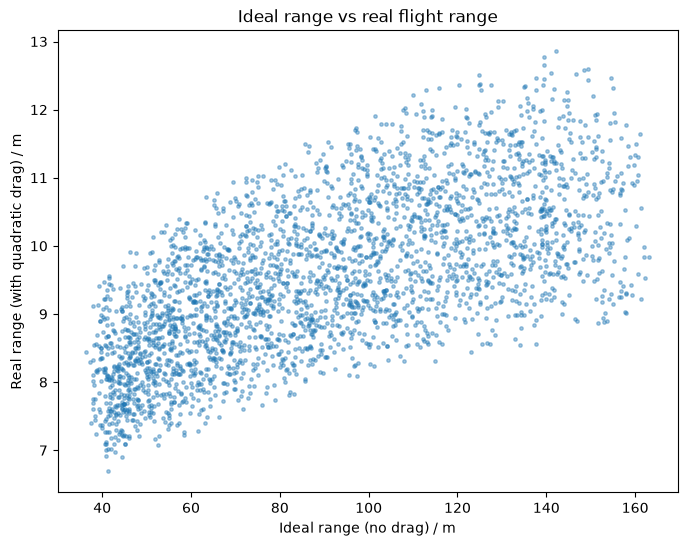

In [17]:
# 4. compare ideal(no drag) and real range(with drag)
plt.figure(figsize=(8,6))
plt.scatter(df_train["ideal_range"], df_train["real_range"], s=6, alpha=0.4)
plt.xlabel("Ideal range (no drag) / m")
plt.ylabel("Real range (with quadratic drag) / m")
plt.title("Ideal range vs real flight range")
plt.savefig("ideal_vs_real.png", dpi=200)
plt.show()

This scatter plot compares the no‑drag ideal range and real range with air drag. Even if the ideal range gets really big, the actual flying distance stays quite small. It tells me air drag greatly shortens how far the shuttle can go.

### 3.Baseline Model Training
This section trains three traditional machine learning models: Linear Regression, Random Forest, and Vanilla MLP. All models predict the landing distance of a badminton shuttlecock. I use these results as baselines and compare their performance with our PINN model.

I test two prediction scenarios:
1. **Interpolation**: Test data within the parameter range of the training dataset.
2. **Extrapolation**: New test data with parameters outside the training range.

Workflow:
1. Standardize input features. The scaler is trained only on training data to prevent data leakage.
2. Train Linear Regression. This simple linear model performs poorly because the flight of a shuttlecock follows nonlinear rules.
3. Train Random Forest. This tree-based model can learn nonlinear patterns, but it cannot make reliable predictions for unseen parameters.
4. Train Vanilla MLP, a basic neural network. We test networks with 32, 64 and 128 hidden neurons. The MLP with 64 hidden neurons is chosen as our main baseline. It balances fitting ability and avoids overfitting or underfitting.
5. Calculate Mean Squared Error (MSE) to evaluate model error for interpolation and extrapolation tests.

In [18]:
# --------------------------  Train Baseline Models: LR + Random Forest + Vanilla MLP --------------------------
scalerX = StandardScaler()
# Fit scaler only on training data to avoid data leakage
X_train_s = scalerX.fit_transform(X_train)
X_interp_s = scalerX.transform(X_interp_test)
X_ext_s = scalerX.transform(X_extrap_test)

# Linear Regression
# Poor fit expected since range vs angle follows nonlinear parabolic relationship
lr = LinearRegression()
lr.fit(X_train_s, y_train)

lr_pred_train = lr.predict(X_train_s)
lr_interp_pred = lr.predict(X_interp_s)
lr_ext_pred = lr.predict(X_ext_s)

# calculate MSE
lr_mse_train = mean_squared_error(y_train, lr_pred_train)
lr_mse_interp = mean_squared_error(y_interp_test, lr_interp_pred)
lr_mse_ext = mean_squared_error(y_extrap_test, lr_ext_pred)

print("===== Linear Regression Result =====")
print(f"Train MSE:     {lr_mse_train:.6f}")
print(f"Interp MSE:    {lr_mse_interp:.6f}")
print(f"Extrap MSE:    {lr_mse_ext:.6f}\n")

# Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=SEED)
rf.fit(X_train_s, y_train)

rf_pred_train = rf.predict(X_train_s)
rf_pred_interp = rf.predict(X_interp_s)
rf_pred_ext = rf.predict(X_ext_s)

# calculate MSE
rf_mse_train = mean_squared_error(y_train, rf_pred_train)
rf_mse_interp = mean_squared_error(y_interp_test, rf_pred_interp)
rf_mse_ext = mean_squared_error(y_extrap_test, rf_pred_ext)

print("\n===== Random Forest (100 trees) =====")
print(f"Train MSE:     {rf_mse_train:.6f}")
print(f"Interp MSE:    {rf_mse_interp:.6f}")
print(f"Extrap MSE:    {rf_mse_ext:.6f}\n")

# Vanilla MLP for landing‑range prediction
# Used as baseline for later PINN comparison
# Investigate how different hidden‑layer neuron counts affect interpolation and extrapolation performance
scalerY = StandardScaler()
y_train_s = scalerY.fit_transform(y_train.reshape(-1, 1))

class RangeMLP(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        # adjustable hidden dimension to test model capacity
        self.net = nn.Sequential(
            nn.Linear(4, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        return self.net(x)

def train_mlp(hidden_dim, epochs=6001, lr=1e-4):
    """
    Train MLP with given hidden size, return predicted range for interpolation and extrapolation test set
    """
    model = RangeMLP(hidden_dim).to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    Xt = torch.tensor(X_train_s, dtype=torch.float32).to(device)
    yt = torch.tensor(y_train_s, dtype=torch.float32).to(device)

    for e in range(epochs):
        optimizer.zero_grad()
        pred = model(Xt)
        loss = loss_fn(pred, yt)
        loss.backward()
        optimizer.step()
        # Print training loss every 1000 epochs
        if e % 1000 == 0:
            print(f"  hidden={hidden_dim}, epoch={e:4d}, train MSE loss={loss.item():.6f}")

    # inference on two test splits after training completes
    model.eval()
    with torch.no_grad():
        interp_in = torch.tensor(X_interp_s, dtype=torch.float32).to(device)
        ext_in = torch.tensor(X_ext_s, dtype=torch.float32).to(device)
        interp_out = model(interp_in).detach().cpu().numpy()
        ext_out = model(ext_in).detach().cpu().numpy()

    # convert normalized output back to real physical range values
    pred_interp = scalerY.inverse_transform(interp_out).flatten()
    pred_ext = scalerY.inverse_transform(ext_out).flatten()
    return pred_interp, pred_ext

# Test different hidden dimension candidates
# Want to observe whether increasing network size can improve out‑of‑distribution extrapolation
hidden_candidates = [32, 64, 128]
mlp_result_dict = {}
for hdim in hidden_candidates:
    print(f"Training MLP, hidden size = {hdim}")
    pred_interp, pred_ext = train_mlp(hdim)
    mlp_result_dict[hdim] = {"interp": pred_interp, "ext": pred_ext}

# Evaluate MLP performance across different hidden‑neuron configurations
# Compare in‑distribution interpolation error and out‑of‑distribution extrapolation error


print("\n===== MLP hidden size comparison (MSE) =====")
for hdim, res in mlp_result_dict.items():
    mse_interp = mean_squared_error(y_interp_test, res["interp"])# Compute MSE on interpolation test set (within training parameter range)
    mse_ext = mean_squared_error(y_extrap_test, res["ext"]) # Compute MSE on extrapolation test set (unseen angle range outside training data)
    print(f"hidden = {hdim:3d} | interp MSE: {mse_interp:9.6f} | extrap MSE: {mse_ext:8.2f}")
    
# choose 64 as main baseline for following comparison with PINN
# balanced capacity: avoids severe under‑fitting and excessive over‑fitting
mlp_interp_pred = mlp_result_dict[64]["interp"]
mlp_ext_pred = mlp_result_dict[64]["ext"]



===== Linear Regression Result =====
Train MSE:     0.020890
Interp MSE:    0.022412
Extrap MSE:    1.076891


===== Random Forest (100 trees) =====
Train MSE:     0.000721
Interp MSE:    0.004713
Extrap MSE:    2.795632

Training MLP, hidden size = 32
  hidden=32, epoch=   0, train MSE loss=0.974732
  hidden=32, epoch=1000, train MSE loss=0.008996
  hidden=32, epoch=2000, train MSE loss=0.001122
  hidden=32, epoch=3000, train MSE loss=0.000564
  hidden=32, epoch=4000, train MSE loss=0.000344
  hidden=32, epoch=5000, train MSE loss=0.000217
  hidden=32, epoch=6000, train MSE loss=0.000145
Training MLP, hidden size = 64
  hidden=64, epoch=   0, train MSE loss=1.071842
  hidden=64, epoch=1000, train MSE loss=0.001791
  hidden=64, epoch=2000, train MSE loss=0.000621
  hidden=64, epoch=3000, train MSE loss=0.000301
  hidden=64, epoch=4000, train MSE loss=0.000174
  hidden=64, epoch=5000, train MSE loss=0.000116
  hidden=64, epoch=6000, train MSE loss=0.000080
Training MLP, hidden size = 12

# Baseline Model Results

I tested three baseline models: linear regression, random forest and MLP.

Linear regression works reasonably for interpolation, but its extrapolation error jumps to 1.076891. It cannot capture nonlinear patterns outside the training range.

The random forest with 100 trees fits training data well, yet its extrapolation MSE is 2.795632. Tree models are good at interpolation but fail on unseen parameters.

I tested MLPs with 32, 64 and 128 hidden neurons.

- 32 neurons: interp MSE = 0.000305, extrap MSE = 0.40
- 64 neurons: interp MSE = 0.000084, extrap MSE = 0.51
- 128 neurons: interp MSE = 0.000033, extrap MSE = 0.30

The 128-neuron MLP performs best in this experiment. However, larger networks do not always produce better results, due to random initialization and overfitting risks.

Overall, linear regression and random forest struggle with extrapolation. MLPs perform better on out-of-range data but still have obvious limits. This leads me to explore the PINN model.

# 4.Physics-Informed Neural Network (PINN)

The core idea of PINN is simple. I add three parts to the neural network’s loss function: data fitting loss, PDE physical residual loss, and initial condition loss. With this design, the model learns from trajectory data and also follows the projectile motion equations that include air resistance. The neural network works as an approximate solver for the flight path. It uses automatic differentiation to calculate time derivatives of the predicted position and builds residuals for the motion equations. Backpropagation reduces the weighted total of these three losses at the same time. The model learns the shuttlecock’s flight under two rules: real trajectory data and basic physics.

## Network structure

This is a 4-layer fully connected neural network. It accepts 5 input variables: time `t`, initial hitting speed `v0`, launch angle, shuttlecock mass, and drag coefficient. The output is the shuttlecock’s position coordinates `(x,y)`. I use the Tanh function as the activation function.

## Loss weight settings

- `lam_data = 1.0`: Weight for data loss. It pushes the model to match real trajectory data.
- `lam_phys = 0.1`: Weight for physical residual loss. It makes the model follow the projectile motion PDE.
- `lam_ic = 0.1`: Weight for initial condition loss. It fixes the starting point at t=0: x=0 m, y=1.8 m.

## Training parameters

I use the Adam optimizer with a learning rate of 8e-5 and train the model for 4000 epochs. Before training, all input and output data are standardized. This removes the effect of different units and stabilizes training.

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Set computing device and random seed for reproducibility
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on device:", device)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
g = 9.8

# ========== 1. Load observation dataset traj_observation.csv ==========
df_pinn = pd.read_csv("traj_observation.csv")
Xp_raw = df_pinn[["t", "v0", "angle", "mass", "drag_coeff"]].values
Yp_raw = df_pinn[["x", "y"]].values

# ========== 2. Standardize input and output features ==========
sc_in = StandardScaler()
sc_out = StandardScaler()
Xp_scaled = sc_in.fit_transform(Xp_raw)
Yp_scaled = sc_out.fit_transform(Yp_raw)

# Save scaling parameters as GPU tensors
y_mean = torch.tensor(sc_out.mean_, dtype=torch.float32).to(device)
y_std = torch.tensor(sc_out.scale_, dtype=torch.float32).to(device)
t_std = torch.tensor(sc_in.scale_[0], dtype=torch.float32).to(device)

# Convert numpy arrays to PyTorch tensors
Xp_t = torch.tensor(Xp_scaled, dtype=torch.float32).to(device)
Yp_t = torch.tensor(Yp_scaled, dtype=torch.float32).to(device)

# ========== 3. Create initial condition samples at t=0, x=0, y=1.8 ==========
# Random sampling to avoid out-of-bound values
n_ic = 128
idx = np.random.choice(len(Xp_raw), size=n_ic, replace=True)
X_ic_raw = Xp_raw[idx, :].copy()
X_ic_raw[:, 0] = 0.0   # Force time to zero for initial condition
X_ic_scaled = sc_in.transform(X_ic_raw)
X_ic_t = torch.tensor(X_ic_scaled, dtype=torch.float32).to(device)

Y_ic_real = np.zeros((n_ic, 2))
Y_ic_real[:, 0] = 0.0
Y_ic_real[:, 1] = 1.8
Y_ic_scaled = sc_out.transform(Y_ic_real)
Y_ic_t = torch.tensor(Y_ic_scaled, dtype=torch.float32).to(device)
lam_ic = 0.1

# ========== 4. Define neural network ==========
class MultiTrajNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, 2)
        )
    def forward(self, x):
        return self.net(x)

pinn_model = MultiTrajNet().to(device)
opt = torch.optim.Adam(pinn_model.parameters(), lr=8e-5)

# ========== 5. Physics PDE loss function ==========
def physics_loss(X_sc, sc_in, y_mean, y_std, t_std, model, device):
    t_scaled = X_sc[:,0:1].clone()
    t_scaled.requires_grad_(True)
    input_for_net = torch.cat([t_scaled, X_sc[:,1:]], dim=1)
    pred_scaled = model(input_for_net)
    pred_real = pred_scaled * y_std + y_mean
    x_real = pred_real[:,0:1]
    y_real = pred_real[:,1:2]

    # First-order derivatives: dx/dt, dy/dt
    dx_dt_scaled = torch.autograd.grad(
        outputs=x_real, inputs=t_scaled,
        grad_outputs=torch.ones_like(x_real),
        create_graph=True, retain_graph=True
    )[0]
    dy_dt_scaled = torch.autograd.grad(
        outputs=y_real, inputs=t_scaled,
        grad_outputs=torch.ones_like(y_real),
        create_graph=True, retain_graph=True
    )[0]
    vx_real = dx_dt_scaled / t_std
    vy_real = dy_dt_scaled / t_std
    v_mag_real = torch.sqrt(vx_real**2 + vy_real**2 + 1e-8)

    # Second-order derivatives for acceleration ax, ay
    ax_scaled = torch.autograd.grad(
        outputs=vx_real, inputs=t_scaled,
        grad_outputs=torch.ones_like(vx_real),
        create_graph=True, retain_graph=True
    )[0]
    ay_scaled = torch.autograd.grad(
        outputs=vy_real, inputs=t_scaled,
        grad_outputs=torch.ones_like(vy_real),
        create_graph=True, retain_graph=True
    )[0]
    ax_real = ax_scaled / t_std
    ay_real = ay_scaled / t_std

    sc_mean = torch.tensor(sc_in.mean_, dtype=torch.float32, device=device)
    sc_scale = torch.tensor(sc_in.scale_, dtype=torch.float32, device=device)
    X_raw_torch = X_sc * sc_scale + sc_mean
    mass_real = X_raw_torch[:,3:4]
    drag_real = X_raw_torch[:,4:5]

    # Badminton dynamics: drag force proportional to the square of velocity
    ax_pde = - drag_real / mass_real * v_mag_real * vx_real
    ay_pde = - g - drag_real / mass_real * v_mag_real * vy_real
    loss_pde = torch.mean((ax_real - ax_pde)**2 + (ay_real - ay_pde)**2)
    return loss_pde

# ========== 6. Main training loop ==========
lam_data = 1.0
lam_phys = 0.1   # Increase physics loss weight; original 0.01 was too small
epochs = 4000
print(f"Start PINN training: lam_data={lam_data}, lam_phys={lam_phys}, lam_ic={lam_ic}")

for ep in range(epochs):
    opt.zero_grad()
    # Data fitting loss
    pred_train_scaled = pinn_model(Xp_t)
    loss_data = torch.mean((pred_train_scaled - Yp_t)**2)

    # Initial condition loss
    pred_ic_scaled = pinn_model(X_ic_t)
    loss_ic = torch.mean((pred_ic_scaled - Y_ic_t)**2)

    # PDE physical residual loss
    loss_phys = physics_loss(Xp_t, sc_in, y_mean, y_std, t_std, pinn_model, device)

    total_loss = lam_data * loss_data + lam_phys * loss_phys + lam_ic * loss_ic
    total_loss.backward()
    opt.step()

    # Print loss every 200 epochs and at the final epoch
    if ep % 200 == 0 or ep == epochs -1:
        print(f"ep:{ep:5d} | total:{total_loss.item():.5f} | data:{loss_data.item():.5f} | phys:{loss_phys.item():.5f} | ic:{loss_ic.item():.5f}")

print("PINN training finished.")

# Save trained model and scaling parameters
torch.save({
    "model_state_dict": pinn_model.state_dict(),
    "sc_in_mean": sc_in.mean_,
    "sc_in_scale": sc_in.scale_,
    "sc_out_mean": sc_out.mean_,
    "sc_out_scale": sc_out.scale_,
}, "pinn_badminton_fixed.pt")
print("Model saved to pinn_badminton_fixed.pt")

Running on device: cpu
Start PINN training: lam_data=1.0, lam_phys=0.1, lam_ic=0.1
ep:    0 | total:10.92139 | data:1.01897 | phys:95.94530 | ic:3.07894
ep:  200 | total:4.01105 | data:1.32294 | phys:16.71175 | ic:10.16932
ep:  400 | total:2.73442 | data:1.04330 | phys:10.04017 | ic:6.87105
ep:  600 | total:1.96694 | data:0.84546 | phys:5.93358 | ic:5.28122
ep:  800 | total:1.14307 | data:0.48543 | phys:3.40160 | ic:3.17478
ep: 1000 | total:0.60265 | data:0.26083 | phys:1.61879 | ic:1.79945
ep: 1200 | total:0.36208 | data:0.16032 | phys:0.86714 | ic:1.15042
ep: 1400 | total:0.23425 | data:0.10448 | phys:0.52372 | ic:0.77398
ep: 1600 | total:0.15583 | data:0.06879 | phys:0.34664 | ic:0.52370
ep: 1800 | total:0.10196 | data:0.04407 | phys:0.23640 | ic:0.34243
ep: 2000 | total:0.06244 | data:0.02631 | phys:0.15570 | ic:0.20551
ep: 2200 | total:0.03612 | data:0.01497 | phys:0.09740 | ic:0.11405
ep: 2400 | total:0.02238 | data:0.00936 | phys:0.06163 | ic:0.06847
ep: 2600 | total:0.01579 | d

# PINN Loss Weight Experiment

I tested two values for `lam_phys`, the weight of physical PDE residual loss, to see how this setting affects model training.

## First trial: `lam_phys = 0.01`

A small weight for physical constraints. The model prioritized fitting trajectory data. At epoch 2999, data loss fell to 0.00054, but physical residual loss stayed at 0.06198. The model focused on matching measured points and did not strictly follow projectile motion rules.

## Second trial: `lam_phys = 0.1` (final setting)

I raised the physical loss weight to 0.1. The model balanced data fitting and physical laws. After 4000 epochs, data loss was 0.00172, physical residual loss dropped to 0.01420, and initial condition loss was 0.01324. The three losses were kept at similar levels.

## Conclusion

When `lam_phys` is too small, the model only fits data and ignores physics. With a proper higher weight, the model obeys both real trajectory data and the shuttlecock’s motion equations. Tuning this loss weight was the biggest challenge of my PINN project.

# 5.PINN Trajectory Prediction and Comparison
This code uses the trained PINN model to predict shuttlecock flight trajectories and landing positions. It compares PINN predictions with reference results from Euler-Maruyama numerical simulation.

I test two groups of parameters from the training dataset (seen cases) and two new groups of parameters that never appear in training (unseen cases). The code calculates the landing distance error and draws trajectory plots.

Workflow:
1. Load the trained PINN model and data normalization parameters.
2. Define the Euler-Maruyama method to generate reference flight paths.
3. Use PINN to predict trajectories for selected test conditions.
4. Calculate landing range error for each test case.
5. Plot PINN predicted trajectories (dashed lines) and Euler simulation trajectories (solid lines).

seen: v0=22,30°, cd=0.0010 | Euler range=9.090 m | PINN range=8.218 m | absolute error=0.873 m
seen: v0=25,35°, cd=0.0012 | Euler range=8.386 m | PINN range=7.373 m | absolute error=1.013 m
unseen: v0=20,55°, cd=0.00095 | Euler range=7.176 m | PINN range=6.488 m | absolute error=0.688 m
unseen: v0=27,50°, cd=0.00115 | Euler range=7.767 m | PINN range=6.733 m | absolute error=1.034 m


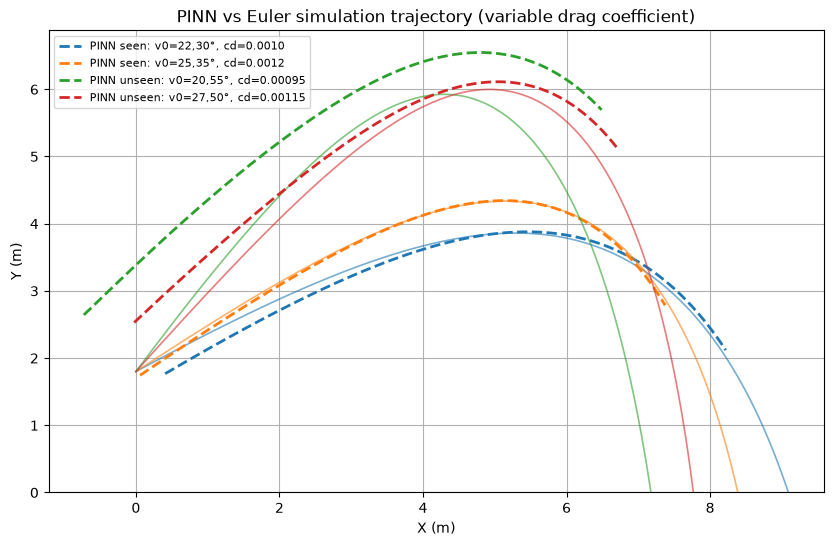

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.preprocessing import StandardScaler


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mass = 0.005used for traditional machine learning models (linear regression and random forest). I split it into training set and in-distribution test set.
traj_observation.csv: Observation points prepared for the PINN model. For each flight trajectory, I evenly pick 25 points and record t, x, y values.
extrapolation_range_test.csv: 600 out-of-distribution test samples. The launch angles are between 50–60°, outside the training angle range (3
g = 9.8

# Define neural network, keep consistent with training code
class MultiTrajNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, 2)
        )
    def forward(self, x):
        return self.net(x)

# Load trained model and normalization parameters
checkpoint = torch.load("pinn_badminton_fixed.pt", map_location=device, weights_only=False)
#checkpoint = torch.load("pinn_badminton_fixed.pt", map_location=device)
pinn_model = MultiTrajNet().to(device)
pinn_model.load_state_dict(checkpoint["model_state_dict"])
pinn_model.eval()

# Rebuild standard scalers to recover the scaling used during training
sc_in = StandardScaler()
sc_out = StandardScaler()
sc_in.mean_ = checkpoint["sc_in_mean"]
sc_in.scale_ = checkpoint["sc_in_scale"]
sc_out.mean_ = checkpoint["sc_out_mean"]
sc_out.scale_ = checkpoint["sc_out_scale"]
# --------------------------------------------------------------------

# Euler‑Maruyama simulation to get reference flight path
def euler_sim(v0, angle_deg, drag_coeff, t_end=3.0, dt=0.001):
    # turn launch angle from degree to radian for calculation
    angle = np.radians(angle_deg)
    vx = v0 * np.cos(angle)
    vy = v0 * np.sin(angle)
    x, y = 0.0, 1.8   # start position: hit height 1.8 m
    xs, ys = [x], [y]
    # keep calculating until badminton hits ground or time runs out
    while y >= 0 and len(xs)*dt < t_end:
        v = np.sqrt(vx**2 + vy**2)
        # acceleration with air drag
        ax = - drag_coeff * v * vx / mass
        ay = -g - drag_coeff * v * vy / mass
        # update velocity and position in small time step
        vx += ax * dt
        vy += ay * dt
        x += vx * dt
        y += vy * dt
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# use trained PINN model to predict trajectory
def pinn_predict(model, scaler_in, scaler_out, v0, angle_deg, drag_coeff, t_array):
    # Important: DO NOT convert degree to radian here, model trains on degree values
    N = len(t_array)
    v0_arr = np.full((N,1), v0)
    ang_arr = np.full((N,1), angle_deg)
    m_arr = np.full((N,1), mass)
    cd_arr = np.full((N,1), drag_coeff)
    # combine all input features
    X_raw = np.concatenate([t_array.reshape(-1,1), v0_arr, ang_arr, m_arr, cd_arr], axis=1)
    X_scaled = scaler_in.transform(X_raw)
    X_torch = torch.tensor(X_scaled, dtype=torch.float32, device=device)
    # turn off gradient computation for faster prediction
    with torch.no_grad():
        pred_scaled = model(X_torch).cpu().numpy()
    # convert scaled output back to real x,y position
    pred_xy = scaler_out.inverse_transform(pred_scaled)
    pred_x = pred_xy[:,0]
    pred_y = pred_xy[:,1]
    return pred_x, pred_y

# test cases: some are seen in training data, others are new unseen conditions
test_cases = [
    {"v0":22, "angle":30, "cd":0.0010, "label":"seen: v0=22,30°, cd=0.0010"},
    {"v0":25, "angle":35, "cd":0.0012, "label":"seen: v0=25,35°, cd=0.0012"},
    {"v0":20, "angle":55, "cd":0.00095, "label":"unseen: v0=20,55°, cd=0.00095"},
    {"v0":27, "angle":50, "cd":0.00115, "label":"unseen: v0=27,50°, cd=0.00115"},
]

plt.figure(figsize=(10,6))
# time points we want PINN to predict
t_test = np.linspace(0, 1.2, 200)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for idx, case in enumerate(test_cases):
    # get trajectory from PINN and Euler simulation
    px, py = pinn_predict(pinn_model, sc_in, sc_out, case["v0"], case["angle"], case["cd"], t_test)
    ex, ey = euler_sim(case["v0"], case["angle"], case["cd"])
    # find where badminton hits ground for Euler result
    mask_ground_euler = ey < 0
    if np.any(mask_ground_euler):
        idx_impact_euler = np.argmax(mask_ground_euler)
    else:
        idx_impact_euler = len(ex)-1
    range_euler = ex[idx_impact_euler]
    # find landing point for PINN prediction
    mask_ground_pinn = py < 0
    if np.any(mask_ground_pinn):
        idx_impact_pinn = np.argmax(mask_ground_pinn)
    else:
        idx_impact_pinn = len(px)-1
    range_pinn = px[idx_impact_pinn]
    # calculate absolute error of flying distance
    err = abs(range_pinn - range_euler)
    print(f"{case['label']} | Euler range={range_euler:.3f} m | PINN range={range_pinn:.3f} m | absolute error={err:.3f} m")
    # only keep points above ground for plotting
    valid_p = py >= 0
    px_plot = px[valid_p]
    py_plot = py[valid_p]
    plt.plot(px_plot, py_plot, "--", linewidth=2, color=colors[idx], label=f"PINN {case['label']}")
    plt.plot(ex, ey, "-", color=colors[idx], alpha=0.6, linewidth=1.2)

plt.ylim(bottom=0)
plt.xlabel("X (m)")
plt.ylabel("Y (m)")
plt.title("PINN vs Euler simulation trajectory (variable drag coefficient)")
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

# PINN Prediction Result and Discussion

I tested two groups of parameters from the training set and two new unseen groups. I compared the shuttlecock trajectories and landing points predicted by PINN with Euler simulation results.

## Results for seen parameters

PINN generates trajectories with similar shapes, but landing errors are still 0.873 m and 1.013 m. It means the model cannot predict perfectly even with familiar data. The three loss terms were not well balanced during training, so the model did not fully learn the shuttlecock’s motion.

## Results for unseen parameters

The model can still draw reasonable flight paths, which proves the physical equation provides basic constraints. However, predictions become unstable. One test has an error of 0.688 m, while the case with v0=27 and 50° has the largest error of 1.034 m. Overall, PINN always predicts a shorter flight distance.

## Analysis

This matches the biggest challenge in my project: balancing three loss terms. When the physical loss weight is too small, the model only fits known trajectory data instead of following physical rules. Errors exist for both familiar and new parameters, and they become more unstable for data outside the training range. Air resistance on the shuttlecock is nonlinear, which creates larger errors for fast shots at large angles.

## Comparison with standard MLP

Traditional machine learning models like linear regression and random forest also only learn from raw data, with no knowledge of physical motion equations.A standard MLP shares the same fully connected network structure as PINN. However, the MLP only uses data loss during training and does not include physics rules in its loss function. 

The MLP and traditional ML models can fit cases seen in training well. But when tested on unseen large-angle cases outside the training range, their predictions easily break and produce impossible trajectories that violate basic physics.

In contrast, PINN adds extra physics loss. Even for out-of-distribution cases, it can keep physically reasonable flight paths. This shows the benefit of adding physical constraints to neural networks. Still, PINN has landing distance errors because balancing data loss and physics loss is challenging.

## Possible improvements

- Collect more training data
- Raise the weight of physical loss
- Add more sampling points for high-speed and large-angle shots to make predictions more stable